In [2]:
%pip install -q kagglehub pandas pyarrow scikit-learn matplotlib seaborn

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import kagglehub
from pathlib import Path
path = Path(kagglehub.dataset_download("dhoogla/unswnb15"))
files = sorted([p for p in path.rglob("*") if p.suffix.lower() in (".parquet", ".csv")])
print("\n".join(str(p.relative_to(path)) for p in files))

UNSW_NB15_testing-set.parquet
UNSW_NB15_training-set.parquet


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay

def load_file(p):
    return pd.read_parquet(p) if p.suffix.lower() == ".parquet" else pd.read_csv(p, low_memory=False)

for p in files:
    try:
        d = load_file(p)
        print(p.name, d.shape, list(d.columns)[-8:])
    except Exception as e:
        print(p.name, str(e)[:160])

UNSW_NB15_testing-set.parquet (82332, 36) ['ct_src_dport_ltm', 'ct_dst_sport_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'is_sm_ips_ports', 'attack_cat', 'label']
UNSW_NB15_training-set.parquet (175341, 36) ['ct_src_dport_ltm', 'ct_dst_sport_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'is_sm_ips_ports', 'attack_cat', 'label']


In [5]:
candidates = [p for p in files if "train" in p.name.lower()]
train_file = candidates[0] if candidates else files[0]
test_candidates = [p for p in files if "test" in p.name.lower() and p != train_file]
test_file = test_candidates[0] if test_candidates else None
df = load_file(train_file)
print(df.shape)
display(df.head())

(175341, 36)


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,...,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,attack_cat,label
0,0.121478,tcp,-,FIN,6,4,258,172,74.087486,14158.942383,...,0,0,1,1,0,0,0,0,Normal,0
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473373,8395.112305,...,0,0,1,1,0,0,0,0,Normal,0
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,1572.271851,...,0,0,1,1,0,0,0,0,Normal,0
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,2740.178955,...,0,0,1,1,1,1,0,0,Normal,0
4,0.449454,tcp,-,FIN,10,6,534,268,33.373825,8561.499023,...,0,0,2,1,0,0,0,0,Normal,0


In [6]:
display(df.head(20))

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,...,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,attack_cat,label
0,0.121478,tcp,-,FIN,6,4,258,172,74.087486,1.415894e+04,...,0,0,1,1,0,0,0,0,Normal,0
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473373,8.395112e+03,...,0,0,1,1,0,0,0,0,Normal,0
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,1.572272e+03,...,0,0,1,1,0,0,0,0,Normal,0
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,2.740179e+03,...,0,0,1,1,1,1,0,0,Normal,0
4,0.449454,tcp,-,FIN,10,6,534,268,33.373825,8.561499e+03,...,0,0,2,1,0,0,0,0,Normal,0
5,0.380537,tcp,-,FIN,10,6,534,268,39.417980,1.011203e+04,...,0,0,2,1,0,0,0,0,Normal,0
6,0.637109,tcp,-,FIN,10,8,534,354,26.683033,6.039783e+03,...,0,0,1,1,0,0,0,0,Normal,0
7,0.521584,tcp,-,FIN,10,8,534,354,32.593025,7.377527e+03,...,0,0,3,1,0,0,0,0,Normal,0
8,0.542905,tcp,-,FIN,10,8,534,354,31.313030,7.087796e+03,...,0,0,3,1,0,0,0,0,Normal,0
9,0.258687,tcp,-,FIN,10,6,534,268,57.985134,1.487512e+04,...,0,0,3,1,0,0,0,0,Normal,0


In [7]:
print(df.dtypes.value_counts())
print(df.isna().sum().sort_values(ascending=False).head(15))
print(df.columns.tolist())

float32     11
int16        9
int8         7
int32        3
int64        2
category     1
category     1
category     1
category     1
Name: count, dtype: int64
dur                  0
proto                0
dwin                 0
tcprtt               0
synack               0
ackdat               0
smean                0
dmean                0
trans_depth          0
response_body_len    0
ct_src_dport_ltm     0
ct_dst_sport_ltm     0
is_ftp_login         0
ct_ftp_cmd           0
ct_flw_http_mthd     0
dtype: int64
['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'is_sm_ips_ports', 'attack_cat', 'label']


label
label
1    119341
0     56000
Name: count, dtype: int64


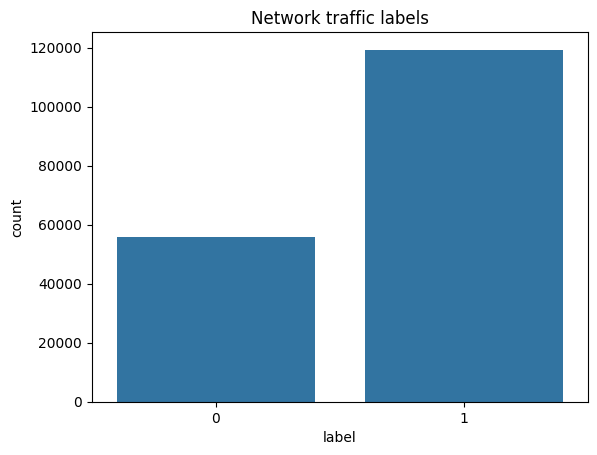

In [8]:
label_col = next((c for c in df.columns if c.lower().strip() in ["label", "attack_label", "is_attack", "class"]), None)
if label_col is None:
    raise ValueError("No binary label column found; inspect the columns printed above.")
print(label_col)
print(df[label_col].value_counts(dropna=False))
sns.countplot(x=df[label_col].astype(str))
plt.title("Network traffic labels")
plt.show()

In [9]:
drop_cols = [label_col] + [c for c in df.columns if c.lower().strip() in ["attack_cat", "attack_category", "attack_type", "id", "index", "unnamed: 0"]]
X = df.drop(columns=drop_cols, errors="ignore")
y = pd.to_numeric(df[label_col], errors="coerce")
if y.isna().any() or set(y.unique()) - {0, 1}:
    raise ValueError("Expected binary labels 0 and 1; inspect target encoding.")
if test_file is not None:
    test_df = load_file(test_file)
    X_test = test_df.reindex(columns=X.columns)
    y_test = pd.to_numeric(test_df[label_col], errors="coerce")
    if y_test.isna().any() or set(y_test.unique()) - {0, 1}:
        raise ValueError("Unexpected labels in test data")
    X_train, y_train = X, y
else:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(175341, 34) (82332, 34)


In [10]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.columns.difference(num_cols).tolist()
num_pipe = Pipeline([("impute", SimpleImputer(strategy="median"))])
cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
prep = ColumnTransformer([("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)])
model = Pipeline([("prep", prep), ("clf", RandomForestClassifier(n_estimators=100, max_depth=18, min_samples_leaf=2, n_jobs=-1, random_state=42, class_weight="balanced_subsample"))])
model.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['dur', 'spkts', 'dpkts',
                                                   'sbytes', 'dbytes', 'rate',
                                                   'sload', 'dload', 'sloss',
                                                   'dloss', 'sinpkt', 'dinpkt',
                                                   'sjit', 'djit', 'swin',
                                                   'stcpb', 'dtcpb', 'dwin',
                                                   'tcprtt', 'synack', 'ackdat',
                                                   'smean', 'dmean',
                                                   'trans_depth',
                                                   'response_body_len',
                                                   'ct_sr...
                                                   'is_ftp_login', 'ct_ftp_cmd',
                                                   'ct_flw_http_mthd', ...]),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encode',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['proto', 'service',
                                                   'state'])])),
                ('clf',
                 RandomForestClassifier(class_weight='balanced_subsample',
                                        max_depth=18, min_samples_leaf=2,
                                        n_jobs=-1, random_state=42))])

              precision    recall  f1-score   support

           0     0.9294    0.8352    0.8798     37000
           1     0.8758    0.9482    0.9106     45332

    accuracy                         0.8974     82332
   macro avg     0.9026    0.8917    0.8952     82332
weighted avg     0.8999    0.8974    0.8967     82332



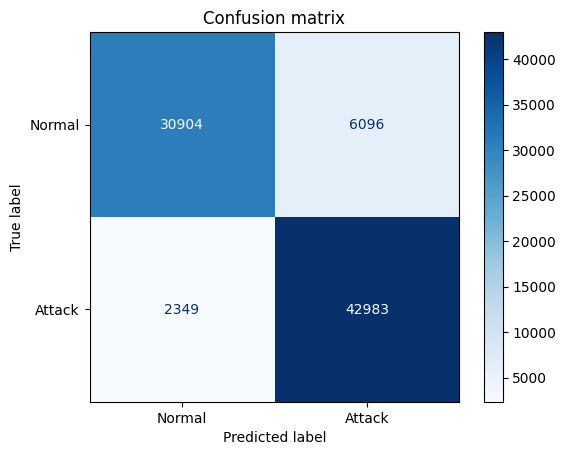

In [11]:
pred = model.predict(X_test)
print(classification_report(y_test, pred, digits=4, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Normal", "Attack"], cmap="Blues")
plt.title("Confusion matrix")
plt.show()

ROC AUC: 0.9798


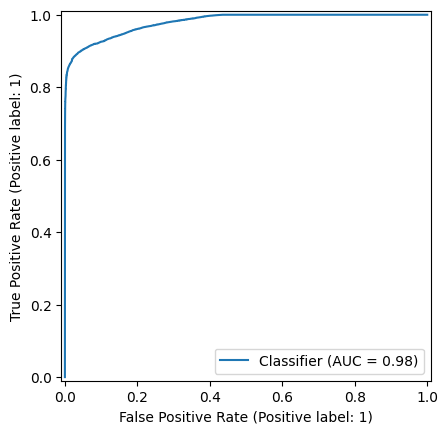

In [12]:
prob = model.predict_proba(X_test)[:, 1]
print("ROC AUC:", round(roc_auc_score(y_test, prob), 4))
RocCurveDisplay.from_predictions(y_test, prob)
plt.show()

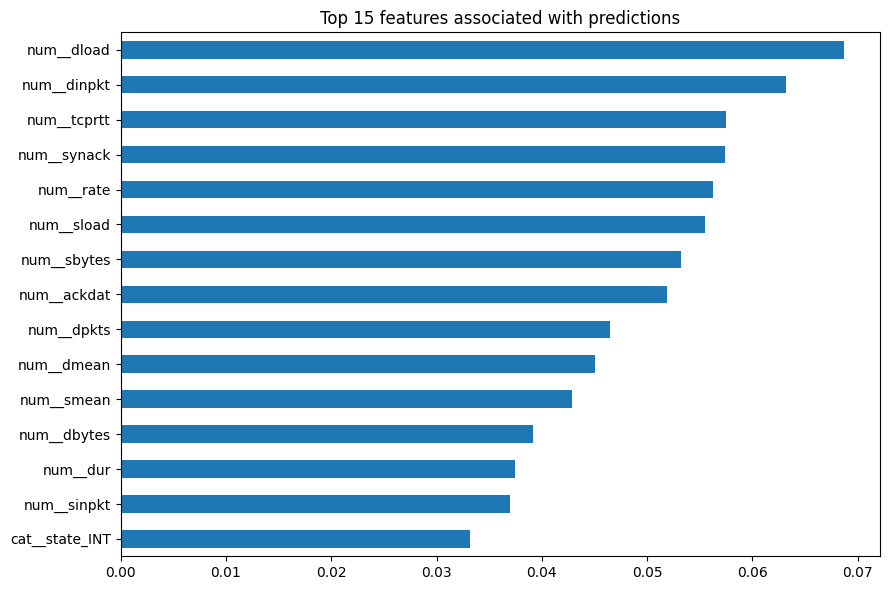

In [13]:
names = model.named_steps["prep"].get_feature_names_out()
importance = pd.Series(model.named_steps["clf"].feature_importances_, index=names).nlargest(15).sort_values()
importance.plot.barh(figsize=(9, 6))
plt.title("Top 15 features associated with predictions")
plt.tight_layout()
plt.show()